In [1]:
import tensorflow as tf
import numpy as np
import pandas as pd
from pylab import rcParams
import matplotlib.pyplot as plt
import warnings

from mlxtend.plotting import plot_decision_regions
from matplotlib.colors import ListedColormap
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dropout
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_circles
import seaborn as sns

<Axes: >

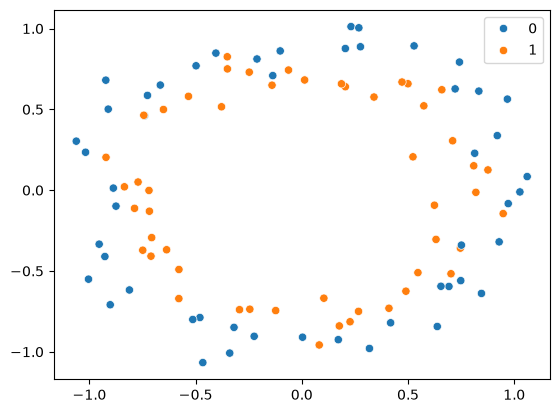

In [3]:
X, y = make_circles(n_samples=100, noise=0.1, random_state=1)
sns.scatterplot(x=X[:, 0], y=X[:, 1], hue=y)

In [4]:
# 2. Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=2)

In [8]:
# 3. Define the Neural Network model
model = Sequential([
    Dense(256, input_dim=2, activation='relu'),
    Dense(1, activation='sigmoid')
])

# 4. Compile the model
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

In [9]:
history = model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=3500, verbose=0)

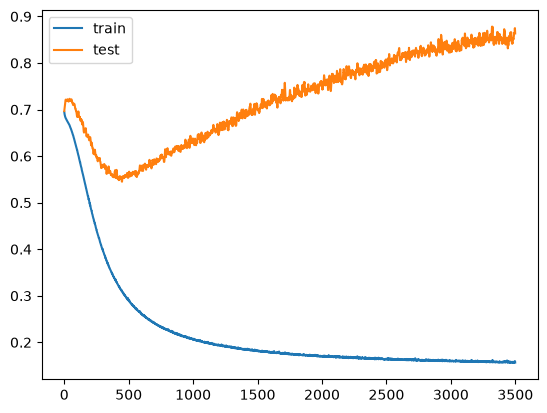

In [10]:
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='test')
plt.legend()
plt.show()

In [ ]:
#Early stopping 

In [11]:
#3. Define the Neural Network model
model = Sequential([
    Dense(256, input_dim=2, activation='relu'),
    Dense(1, activation='sigmoid')
])

# 4. Compile the model
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# 5. Define Early Stopping Callback
callback = EarlyStopping(
    monitor='val_loss',
    min_delta=0.001,
    patience=3,
    verbose=1,
    mode='auto',
    restore_best_weights=False
)

In [12]:
history = model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=3500, callbacks=callback)

Epoch 1/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 162ms/step - accuracy: 0.5000 - loss: 0.6958 - val_accuracy: 0.5000 - val_loss: 0.6916
Epoch 2/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.4875 - loss: 0.6933 - val_accuracy: 0.5000 - val_loss: 0.6932
Epoch 3/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.5125 - loss: 0.6914 - val_accuracy: 0.3500 - val_loss: 0.6955
Epoch 4/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.5125 - loss: 0.6899 - val_accuracy: 0.3500 - val_loss: 0.6974
Epoch 4: early stopping


2601/2601 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step


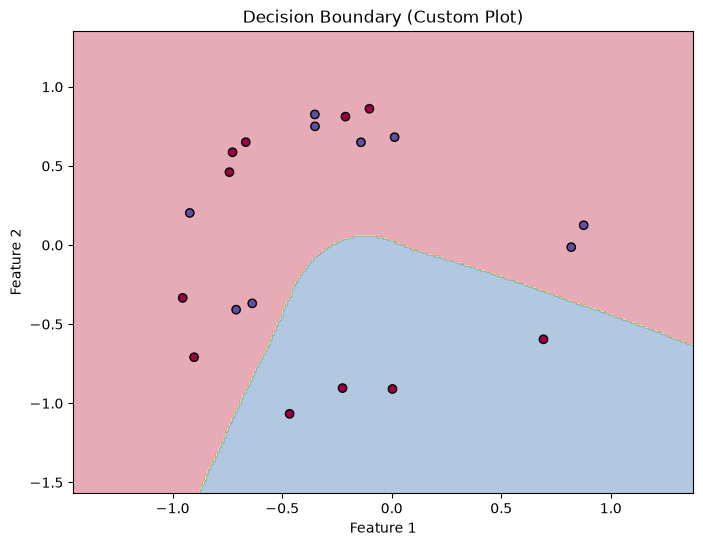

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Grid points create karein X_test ke min aur max range ke hisaab se
x_min, x_max = X_test[:, 0].min() - 0.5, X_test[:, 0].max() + 0.5
y_min, y_max = X_test[:, 1].min() - 0.5, X_test[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01),
                     np.arange(y_min, y_max, 0.01))

# 2. Model se grid ke har point par prediction nikalein
grid_points = np.c_[xx.ravel(), yy.ravel()]
Z = model.predict(grid_points)
Z = Z.reshape(xx.shape)
Z = np.where(Z >= 0.5, 1, 0) # Binary classification ke liye threshold 0.5

# 3. Contour plot aur Scatter plot banayein
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.4, cmap=plt.cm.Spectral)

# Test data ko scatter plot par dikhayein
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap=plt.cm.Spectral, edgecolors='k')
plt.title("Decision Boundary (Custom Plot)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [21]:
import IPython

# 1. Automatically save the current notebook checkpoint
IPython.get_ipython().run_cell_magic('javascript', '', 'IPython.notebook.save_checkpoint();')

# 2. Add, commit, and push automatically to whichever repo you are in
!git add .
!git commit -m "Auto-update notebooks"
!git push origin main

<IPython.core.display.Javascript object>

[main b26f7df] Auto-update notebooks
 4 files changed, 740 insertions(+), 3 deletions(-)
 create mode 100644 .ipynb_checkpoints/Early_stopping in NN-checkpoint.ipynb
 create mode 100644 Early_stopping in NN.ipynb


To https://github.com/devanshnigam2004-bit/Practice_DL.git
   a01d48a..b26f7df  main -> main
